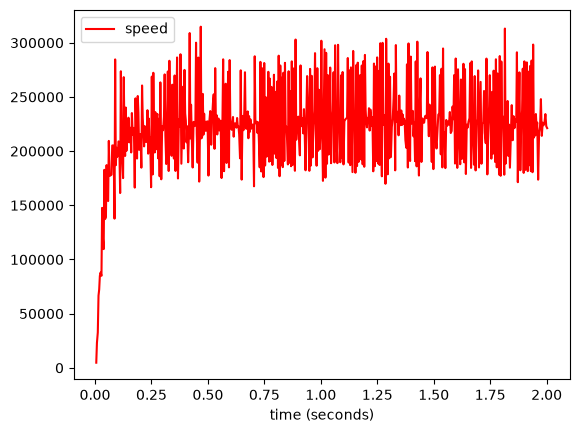

In [4]:
#
# sample_motor_data
#

import arslabrobotics as ar

motor = ar.system.MotorDriver()
motor.open()
motor.reset()

dp = ar.data.DataPlotter()
dp.set_x("time (seconds)")
dp.add_y("speed", "speed")

f = 5000

data_file = open("motor_data_1000.txt", "w")

t = ar.utils.Time()

t.start()
prev_enc = 0
motor.pwm(f)
while t.get() < 2:

    t.sleep(0.001)
    enc = motor.encoder()
    delta_t = t.elapsed()

    speed = (enc - prev_enc) / delta_t
    prev_enc = enc
    dp.append_x(t.get())
    dp.append_y("speed", speed)
    
    data_file.write(f"{f} {speed}\n")

motor.pwm(0)
dp.plot()
data_file.close()
